In [1]:
import os
import re
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

In [2]:
file_path = r"C:\Users\minsa_\Downloads\dataset_final_merged.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (591, 83)


In [3]:
print("Number of columns:", len(df.columns))

for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

Number of columns: 83
1. Tissue_ID
2. Eye
3. Image_ID
4. Disease_Label
5. Disease_Severity
6. ECD_CD_cells_per_mm2
7. CV
8. HEX_percent
9. SD
10. Total_Cell_Count
11. Total_Area_um2
12. Epithelium_Findings
13. Epithelium_Severity
14. Stroma_Findings
15. Stroma_Severity
16. Descemet_Findings
17. Descemet_Severity
18. Endothelium_Findings
19. Endothelium_Severity
20. Additional_Findings
21. Tissue_Grade
22. Overall_Donor_Quality
23. Transplant_Suitability
24. Suitability_Reason
25. Primary_COD
26. Donor_Age
27. Data_Source
28. Notes
29. Tissue_Serial
30. Linkage_Status
31. Form_Transcription_Status
32. Source_PDF
33. PDF_Pages
34. Konan_Report_File
35. SP_Image_File
36. Cell_Image_File
37. Konan_Raw_CorneaID
38. Konan_Exam_Date
39. Konan_Mean_Cell_Area_um2
40. Konan_Comments
41. Donor_Sex
42. Admitting_Diagnosis
43. Death_Date_Time
44. Preservation_Date_Time
45. Death_to_Preservation_Time
46. Storage_Medium
47. Serology_HBsAg
48. Serology_HCV
49. Serology_HIV
50. Serology_VDRL
51. Lens_S

In [4]:
df.head()

,Tissue_ID,Eye,Image_ID,Disease_Label,Disease_Severity,ECD_CD_cells_per_mm2,CV,HEX_percent,SD,Total_Cell_Count,Total_Area_um2,Epithelium_Findings,Epithelium_Severity,Stroma_Findings,Stroma_Severity,Descemet_Findings,Descemet_Severity,Endothelium_Findings,Endothelium_Severity,Additional_Findings,Tissue_Grade,Overall_Donor_Quality,Transplant_Suitability,Suitability_Reason,Primary_COD,Donor_Age,Data_Source,Notes,Tissue_Serial,Linkage_Status,Form_Transcription_Status,Source_PDF,PDF_Pages,Konan_Report_File,SP_Image_File,Cell_Image_File,Konan_Raw_CorneaID,Konan_Exam_Date,Konan_Mean_Cell_Area_um2,Konan_Comments,Donor_Sex,Admitting_Diagnosis,Death_Date_Time,Preservation_Date_Time,Death_to_Preservation_Time,Storage_Medium,Serology_HBsAg,Serology_HCV,Serology_HIV,Serology_VDRL,Lens_Status,Form_ECD_cells_per_mm2,Intended_Use,Tissue_Outcome,Recipient_Age,Recipient_Eye,Recipient_Indication,Request_Indication,Previous_Grafts,Primary_Procedure,Secondary_Procedures,Surgery_Date,Donor_Graft_Size_mm,Recipient_Bed_Size_mm,Suture_Technique,Intraop_Complications,Death_to_Surgery_Days,Request_Reg_No,Request_Issue_No,Request_Date,Proposed_Op_Date,Request_Urgency,Request_Indication_Type,Recipient_Sex,VA_Operative_Eye,VA_Fellow_Eye,Requested_Grade,Planned_Procedure,Requesting_Surgeon,Requesting_Hospital,Request_Capture_Status,Request_to_Surgery_Days,Grade_Request_Met
0,12346 R (year/month unknown),Right,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No Konan report/image found for this form,12346,Form only (no Konan/image),Pending - handwritten form fields not yet entered,12346R.pdf,2,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NEB-2020-09-12654 R,Right,NEB-2020-09-12654 R_SP,NaN,NaN,2132.0,33.0,58.0,153.0,24.0,11266.0,Clear and intact,NaN,Clear; arcus,Mild,Folds,Mild,NaN,NaN,Rim 3.5; cornea diameter 11 mm; corneoscleral ...,B,NaN,NaN,NaN,Disseminated carcinoma of oesophagus,57.0,Konan report + Handwritten forms (Tissue Infor...,NaN,12654,Linked: form + Konan + image,Transcribed by Claude from scan - VERIFY again...,12654R.pdf,6,NEB-2020-09-12654 RT.txt,NEB-2020-09-12654 R_SP.jpg,NEB-2020-09-12654 R_C.jpg,NEB-2020-09-12654 R,2020-09-14,469.0,T.H.KU/GALA-WD.50-ONCOLOGY,Male,Carcinoma of oesophagus,2020-09-13 12:20:00,2020-09-13 14:50:00,2 h 30 min,Eusol-C,Negative,Negative,Negative,Negative,NaN,2132,NaN,NaN,NaN,Right,NaN,Therapeutic,NaN,Lamellar keratoplasty (DALK),NaN,2020-09-18,8.25,8,Interrupted,NaN,5.0,NaN,NaN,NaT,NaT,NaN,Therapeutic,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Partial - carried over from main sheet; re-rea...,NaN,NaN
2,NEB-2020-09-12655 L,Left,NEB-2020-09-12655 L_SP,NaN,NaN,2212.0,33.0,47.0,147.0,70.0,31637.0,"Exposure; peripheral (""mild exposure"")",Mild,Arcus,NaN,NaN,NaN,NaN,NaN,Rim 3.5; cornea diameter 11 mm; corneoscleral ...,B,NaN,NaN,NaN,Disseminated carcinoma of oesophagus,57.0,Konan report + Handwritten forms (Tissue Infor...,NaN,12655,Linked: form + Konan + image,Transcribed by Claude from scan - VERIFY again...,12655L.pdf,5,NEB-2020-09-12655 LT.txt,NEB-2020-09-12655 L_SP.jpg,NEB-2020-09-12655 L_C.jpg,NEB-2020-09-12655 L,2020-09-14,452.0,T.H.KU/GALA-WD.50-ONCOLOGY,Male,Carcinoma of oesophagus,NaT,NaT,2 h 30 min,NaN,NaN,NaN,NaN,NaN,NaN,2212,NaN,Cornea expired 27-09-2020 (handwritten note),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NEB-2020-09-12656 R,Right,NEB-2020-09-12656 R_SP,NaN,NaN,2538.0,35.0,53.0,137.0,136.0,53575.0,Clear and intact,NaN,Clear; arcus,Mild,Folds,Mild,Stress lines; central; few,NaN,Rim 1.5-2; cornea diameter 11 mm; corneosclera...,A,Excellent,Suitable,NaN,Basilar artery thrombosis + cerebral infarction,51.0,Konan report + Handwritten forms (Tissue Infor...,NaN,12656,Linked: form + Konan + image,Transcribed by Claude from scan - VERIFY ag

In [5]:
df.tail()

,Tissue_ID,Eye,Image_ID,Disease_Label,Disease_Severity,ECD_CD_cells_per_mm2,CV,HEX_percent,SD,Total_Cell_Count,Total_Area_um2,Epithelium_Findings,Epithelium_Severity,Stroma_Findings,Stroma_Severity,Descemet_Findings,Descemet_Severity,Endothelium_Findings,Endothelium_Severity,Additional_Findings,Tissue_Grade,Overall_Donor_Quality,Transplant_Suitability,Suitability_Reason,Primary_COD,Donor_Age,Data_Source,Notes,Tissue_Serial,Linkage_Status,Form_Transcription_Status,Source_PDF,PDF_Pages,Konan_Report_File,SP_Image_File,Cell_Image_File,Konan_Raw_CorneaID,Konan_Exam_Date,Konan_Mean_Cell_Area_um2,Konan_Comments,Donor_Sex,Admitting_Diagnosis,Death_Date_Time,Preservation_Date_Time,Death_to_Preservation_Time,Storage_Medium,Serology_HBsAg,Serology_HCV,Serology_HIV,Serology_VDRL,Lens_Status,Form_ECD_cells_per_mm2,Intended_Use,Tissue_Outcome,Recipient_Age,Recipient_Eye,Recipient_Indication,Request_Indication,Previous_Grafts,Primary_Procedure,Secondary_Procedures,Surgery_Date,Donor_Graft_Size_mm,Recipient_Bed_Size_mm,Suture_Technique,Intraop_Complications,Death_to_Surgery_Days,Request_Reg_No,Request_Issue_No,Request_Date,Proposed_Op_Date,Request_Urgency,Request_Indication_Type,Recipient_Sex,VA_Operative_Eye,VA_Fellow_Eye,Requested_Grade,Planned_Procedure,Requesting_Surgeon,Requesting_Hospital,Request_Capture_Status,Request_to_Surgery_Days,Grade_Request_Met
586,NEB-2025-11-17646 L,Left,NEB-2025-11-17646 L_SP,NaN,NaN,2309.0,38.0,50.0,164.0,112.0,48442.0,Nothing ticked; other comments: mild ED,NaN,Clear; diameter of clear area 8 mm,NaN,Folds (mild); relative number mild,Mild,Stress lines; central; few,NaN,Rim 3.5-4; cornea diameter 11 mm; corneosclera...,A,Very good,Suitable,NaN,Aspiration pneumonia,71.0,Konan report + Handwritten forms (Tissue Infor...,Fellow eye of 17645 R (same donor). Donor sex ...,17646,Linked: form + Konan + image,Transcribed by Claude from scan - VERIFY again...,17646_L.pdf,3,NEB-2025-11-17646 LT.txt,NEB-2025-11-17646 L_SP.jpg,NEB-2025-11-17646 L_C.jpg,NEB-2025-11-17646 L,2025-11-09,433.0,NHK-WD 35,"Verify - Male ticked, title ""Mrs""",Aspiration pneumonia (WBC 18.33 x10^3 on 2025-...,2025-11-08 08:20:00,2025-11-08 09:45:00,1 h 25 min,Optisol GS ticked on Donor Form B - lot P25070...,Negative,Negative,Negative,Negative,Not marked,2309,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No request form in PDF,NaN,NaN
587,NEB-2025-11-17647 R,Right,NEB-2025-11-17647 R_SP,NaN,NaN,2294.0,37.0,50.0,162.0,110.0,47976.0,Nothing ticked,NaN,Clear; compact; diameter of clear area 8 mm; s...,NaN,Folds (mild); relative number mild,Mild,Stress lines; central; few,NaN,Rim 3-3.5; cornea diameter 11 mm; corneosclera...,A,Very good,Suitable,NaN,Carcinoma of lung with brain metastases,73.0,Konan report + Handwritten forms (Tissue Infor...,Fellow eye of 17648 L (same donor). Pseudophak...,17647,Linked: form + Konan + image,Transcribed by Claude from scan - VERIFY again...,17647_R.pdf,3,NEB-2025-11-17647 RT.txt,NEB-2025-11-17647 R_SP.jpg,NEB-2025-11-17647 R_C.jpg,NEB-2025-11-17647 R,2025-11-09,436.0,NHK-WD 48,Male,Known patient with carcinoma of lung (WBC 17.2...,2025-11-08 07:30:00,2025-11-08 09:20:00,1 h 50 min,Optisol GS ticked on Donor Form B - lot P25070...,Negative,Negative,Negative,Negative,Pseudophakic (circled),2294,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No request form in PDF,NaN,NaN
588,NEB-2025-11-17648 L,Left,NEB-2025-11-17648 L_SP,NaN,NaN,2755.0,45.0,47.0,164.0,120.0,43603.0,Exposure (mild); location central/peripheral (...,Mild,"Clear; compact; arcus (mild, as read); diamete...",NaN,Folds (mild); relative number mild,Mild,Stress lines; central; few,NaN,Rim 2.5-3.5; cornea diameter 11 mm; corneoscle...,A+,Excellent,Suitable,NaN,Carcinoma of lung with brain metastases,73.0,Konan report + Handwritten forms (Tissue Infor...,Fellow eye of 17647 R (same donor). Donor sex ...,17648,Linked: form + Konan

In [6]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Disease_Label,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Disease_Severity,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ECD_CD_cells_per_mm2,493.0,2650.58215,676.0,2387.0,2639.0,2924.0,4484.0,455.624118
CV,493.0,38.306288,25.0,35.0,38.0,41.0,74.0,5.23488
HEX_percent,493.0,53.74645,27.0,50.0,54.0,58.0,72.0,6.49066
SD,492.0,150.489837,86.0,125.0,142.0,162.0,753.0,49.564806
Total_Cell_Count,493.0,106.450304,12.0,104.0,107.0,113.0,153.0,15.606833
Total_Area_um2,493.0,41137.162272,5418.0,36526.0,40780.0,45592.0,84624.0,8549.437633
Donor_Age,589.0,59.813243,18.0,54.0,62.0,69.0,78.0,10.702331
Tissue_Serial,591.0,15524.964467,12346.0,12986.0,16126.0,17494.5,17650.0,1921.477931


In [7]:
df.describe(include="object").T

,count,unique,top,freq
Tissue_ID,591,591,12346 R (year/month unknown),1
Eye,591,2,Left,297
Image_ID,549,549,NEB-2020-09-12654 R_SP,1
Epithelium_Findings,587,410,Clear and intact,37
Epithelium_Severity,314,7,Mild,298
Stroma_Findings,588,306,Clear; arcus; diameter of clear area 8 mm,18
Stroma_Severity,415,7,Mild,393
Descemet_Findings,586,77,Folds; relative number: mild,100
Descemet_Severity,567,8,Mild,516
Endothelium_Findings,575,124,Stress lines; central; few,96


In [8]:
print("Shape:", df.shape)

Shape: (591, 83)


In [9]:
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

1. Tissue_ID
2. Eye
3. Image_ID
4. Disease_Label
5. Disease_Severity
6. ECD_CD_cells_per_mm2
7. CV
8. HEX_percent
9. SD
10. Total_Cell_Count
11. Total_Area_um2
12. Epithelium_Findings
13. Epithelium_Severity
14. Stroma_Findings
15. Stroma_Severity
16. Descemet_Findings
17. Descemet_Severity
18. Endothelium_Findings
19. Endothelium_Severity
20. Additional_Findings
21. Tissue_Grade
22. Overall_Donor_Quality
23. Transplant_Suitability
24. Suitability_Reason
25. Primary_COD
26. Donor_Age
27. Data_Source
28. Notes
29. Tissue_Serial
30. Linkage_Status
31. Form_Transcription_Status
32. Source_PDF
33. PDF_Pages
34. Konan_Report_File
35. SP_Image_File
36. Cell_Image_File
37. Konan_Raw_CorneaID
38. Konan_Exam_Date
39. Konan_Mean_Cell_Area_um2
40. Konan_Comments
41. Donor_Sex
42. Admitting_Diagnosis
43. Death_Date_Time
44. Preservation_Date_Time
45. Death_to_Preservation_Time
46. Storage_Medium
47. Serology_HBsAg
48. Serology_HCV
49. Serology_HIV
50. Serology_VDRL
51. Lens_Status
52. Form_ECD_cel

In [10]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

missing = missing.sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing

,Missing_Count,Missing_Percentage
Disease_Label,591,100.000000
Disease_Severity,591,100.000000
Suitability_Reason,587,99.323181
Tissue_Outcome,539,91.201354
Previous_Grafts,518,87.648054
Secondary_Procedures,506,85.617597
Endothelium_Severity,504,85.279188
VA_Fellow_Eye,496,83.925550
VA_Operative_Eye,492,83.248731
Intraop_Complications,485,82.064298


In [11]:
missing[missing["Missing_Count"] > 0]

,Missing_Count,Missing_Percentage
Disease_Label,591,100.000000
Disease_Severity,591,100.000000
Suitability_Reason,587,99.323181
Tissue_Outcome,539,91.201354
Previous_Grafts,518,87.648054
Secondary_Procedures,506,85.617597
Endothelium_Severity,504,85.279188
VA_Fellow_Eye,496,83.925550
VA_Operative_Eye,492,83.248731
Intraop_Complications,485,82.064298


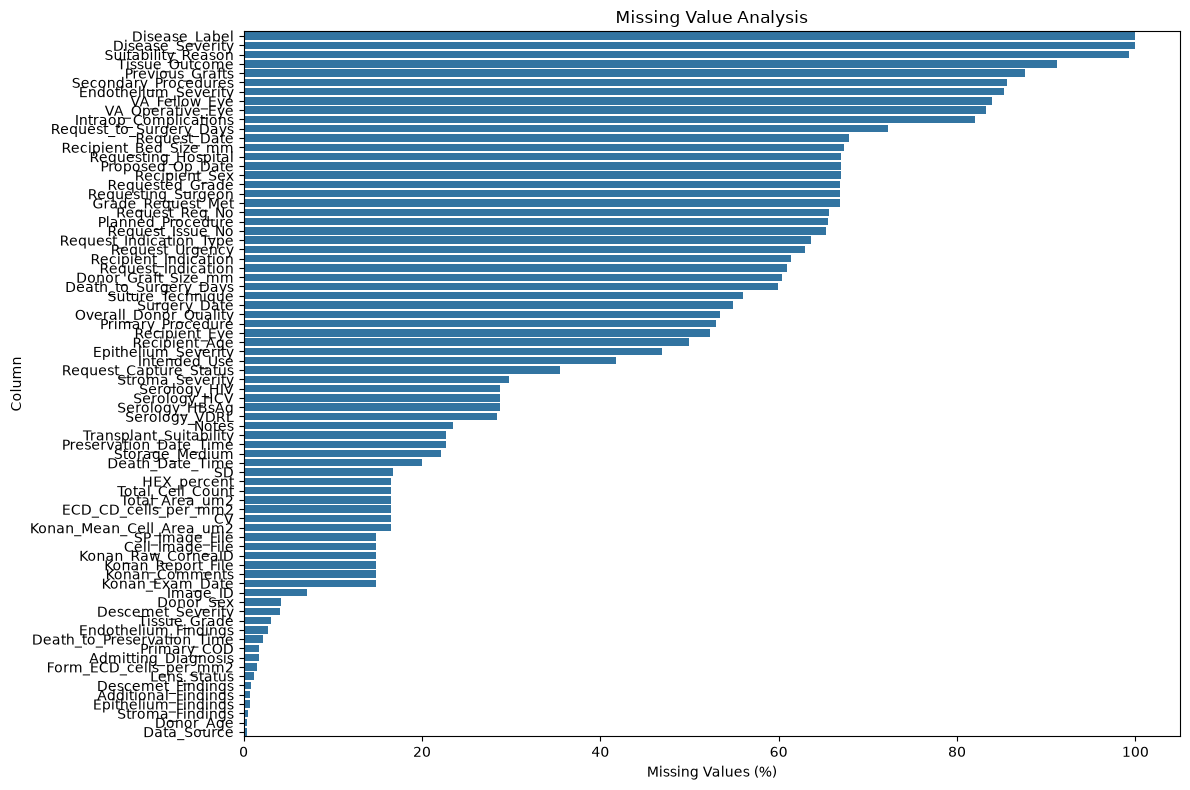

In [12]:
plt.figure(figsize=(12, 8))

missing_plot = missing[missing["Missing_Count"] > 0]

sns.barplot(
    x=missing_plot["Missing_Percentage"],
    y=missing_plot.index
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.title("Missing Value Analysis")
plt.tight_layout()
plt.show()